In [1]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd
import geopandas as geopd


# =========================
# Geometry / GIS
# =========================
import shapely.wkt as wkt

from shapely.geometry import LineString, Polygon, Point

import mapclassify


# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_pickle('../../../../Data/e2018.pkl')
df.rename(columns={'BADGE':'badge'},inplace=True)
df.rename(columns={'DATE_RD':'date'},inplace=True)
df1 = pd.read_csv("../../../../Data/household_data/badge_location.csv")
df = pd.merge(df,df1[['badge','tractID','blockID']],on='badge',how='left')
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df[df["date"].dt.month == 4]
df = df.dropna(subset=["blockID", "tractID"]).reset_index(drop=True)
df["blockID"] = df["blockID"].astype(int)
df["tractID"] = df["tractID"].astype(int)
df["blockID"] = df["blockID"].astype(str)
df['blockgroupID'] = df['blockID'].str[:5]
df["tractID"] = df["tractID"].astype(str)
df.index = range(df.shape[0])
df.head(2)

,badge,date,INT_VALUE_0000,INT_VALUE_0030,INT_VALUE_0100,INT_VALUE_0130,INT_VALUE_0200,INT_VALUE_0230,INT_VALUE_0300,INT_VALUE_0330,INT_VALUE_0400,INT_VALUE_0430,INT_VALUE_0500,INT_VALUE_0530,INT_VALUE_0600,INT_VALUE_0630,INT_VALUE_0700,INT_VALUE_0730,INT_VALUE_0800,INT_VALUE_0830,INT_VALUE_0900,INT_VALUE_0930,INT_VALUE_1000,INT_VALUE_1030,INT_VALUE_1100,INT_VALUE_1130,INT_VALUE_1200,INT_VALUE_1230,INT_VALUE_1300,INT_VALUE_1330,INT_VALUE_1400,INT_VALUE_1430,INT_VALUE_1500,INT_VALUE_1530,INT_VALUE_1600,INT_VALUE_1630,INT_VALUE_1700,INT_VALUE_1730,INT_VALUE_1800,INT_VALUE_1830,INT_VALUE_1900,INT_VALUE_1930,INT_VALUE_2000,INT_VALUE_2030,INT_VALUE_2100,INT_VALUE_2130,INT_VALUE_2200,INT_VALUE_2230,INT_VALUE_2300,INT_VALUE_2330,address,district,tractID,blockID,blockgroupID
0,E162956,2018-04-01,1.62,1.45,1.44,1.59,1.18,0.75,0.95,0.80,0.79,0.75,0.76,0.77,0.89,0.78,1.16,2.04,3.90,2.18,0.80,0.34,0.31,0.13,0.14,0.26,0.22,0.38,0.14,0.29,0.11,0.14,0.16,0.15,0.26,0.14,0.17,0.17,0.19,0.28,0.24,0.17,0.17,0.14,0.22,0.30,0.14,0.13,0.15,0.31,46.0,POINT (-84.30334 30.388433),1801,18011011,18011
1,E162956,2018-04-02,0.17,0.15,0.16,0.27,0.13,0.16,0.11,0.13,0.29,0.12,0.14,0.10,0.31,0.09,0.18,0.55,0.88,0.60,0.54,0.52,0.88,0.21,0.61,1.87,2.68,2.51,2.52,2.25,0.17,0.42,0.18,0.18,0.31,0.22,0.33,0.27,0.66,0.11,0.42,0.49,1.00,0.92,0.26,0.34,0.64,0.21,0.38,0.16,46.0,POINT (-84.30334 30.388433),1801,18011011,18011


In [3]:
boundary_block = pd.read_csv('../../../../Data/boundary_data/tal_block_boundary.csv')
boundary_block["geometry"] = geopd.GeoSeries.from_wkt(boundary_block["geometry"])
boundary_block = geopd.GeoDataFrame(boundary_block, crs="EPSG:4326")
boundary_block["centroid"] = geopd.GeoSeries.from_wkt(boundary_block["centroid"])
boundary_block.head(2)

,tractID,blockID,geoID,geometry,centroid
0,2505,25054048,120730025054048,"POLYGON ((-84.21645 30.45289, -84.21638 30.452...",POINT (-84.21505 30.45322)
1,1801,18012017,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094)


In [4]:
boundary_block_group = boundary_block.copy()
boundary_block_group["blockgroupID"] = boundary_block_group["blockID"].astype(str).str[:5]
boundary_block_group = boundary_block_group[['tractID','blockID','blockgroupID','geoID','geometry','centroid']]

In [5]:
id_cols = ["badge", "date", "address", "district", "tractID", "blockID",'blockgroupID']

value_cols = [c for c in df.columns if c.startswith("INT_VALUE_")]
# 若 df 构造时保证列顺序就是 0000→2330，可不用再 sort；否则会乱序时按时间后缀排序更安全：
value_cols = sorted(value_cols)

assert len(value_cols) == 48, len(value_cols)

# 形状 (行数, 6 个四小时段, 每段 8 个半小时点) → 在最后一维求和 → (行数, 6)
arr_4h = df[value_cols].to_numpy(dtype="float64").reshape(len(df), 6, 8).sum(axis=2)

new_cols = [
    "INT_4h_1",  # 00:00–03:30
    "INT_4h_2",
    "INT_4h_3",
    "INT_4h_4",
    "INT_4h_5",
    "INT_4h_6",
]

df1 = pd.concat([df[id_cols].reset_index(drop=True), pd.DataFrame(arr_4h, columns=new_cols)], axis=1)

In [6]:
import pandas as pd
import numpy as np

value_cols = [f"INT_4h_{i}" for i in range(1, 7)]
meta_cols = ["address", "district", "tractID", "blockID",'blockgroupID']

base = df1.copy()
base["day"] = pd.to_datetime(base["date"], errors="coerce").dt.normalize()

# （可选）同一天同一 badge 若有多条，先按业务规则聚合：这里用最常见的“求和”，你可改成 mean/first 等。
base = (
    base.groupby(["badge", "day"], as_index=False)[value_cols + meta_cols]
    .agg({**{c: "sum" for c in value_cols}, **{c: "first" for c in meta_cols}})
)

badges = np.sort(base["badge"].unique())

# TODO: 用你的 30 天替换这里（要包含你希望对齐的那 30 个 calendar day）
day_range = pd.date_range("2018-04-01", periods=30, freq="D").normalize()

idx = pd.MultiIndex.from_product([badges, day_range], names=["badge", "day"])

wide06 = (
    base.set_index(["badge", "day"])[value_cols]
    .reindex(idx)
    .fillna(0)
)

# （可选自检）理论上每个 badge 正好 30 行 × 6 列 → 180
assert wide06.groupby(level=0).size().eq(30).all(), "badge-day 不完整，请检查 day_range"

# （badge，day）已按字典序：先 badge，再日期；对每个 badge，30 天的 6 列按行展开成 180
n_badge = badges.size
n_day = day_range.size
arr180 = wide06.to_numpy(dtype=float).reshape(n_badge, n_day * 6)

# 列名也可用 f"{day}_{k}"；这里给一个简单的 t000 ~ t179
col180 = [f"t{i:03d}" for i in range(180)]

meta = (
    base.sort_values(["badge", "day"])
        .drop_duplicates("badge")
        .set_index("badge")[meta_cols]
    .reindex(badges)  # 与 badges 对齐
)

df2 = pd.concat(
    [
        meta,
        pd.DataFrame(arr180, index=badges, columns=col180),
    ],
    axis=1,
).reset_index(names="badge")   # pandas>=2；若报错可改成 reset_index().rename(...)

In [7]:
import re
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols)  # t000,t001,...,t179
X = df2[feat_cols].to_numpy(dtype=np.float64)  # 形状 (N, 180)
assert X.shape[1] == 180
assert X.shape[0] == len(df2)

z = np.asarray(X, dtype=float).ravel()
z = z[np.isfinite(z)]
thresh_high = np.quantile(z, 0.90)    
print(f"90% 阈值: {thresh_high:.2f}")

thresh_low = np.quantile(z, 0.05)    
print(f"5% 阈值: {thresh_low:.2f}")    

90% 阈值: 9.98
5% 阈值: 0.12


In [8]:
import re
import numpy as np
# 选出 180 个特征列（按你实际的列命名改这里的规则）
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols, key=lambda x: int(str(x)[1:]))
assert len(feat_cols) == 180, len(feat_cols)
X = df2[feat_cols].to_numpy(dtype=float)
# 每个 badge（每一行）：180 个数里有多少 > thresh
prop = np.mean(X > thresh_high, axis=1)
df2["prop_high"] = prop

In [9]:
import re
import numpy as np
# 选出 180 个特征列（按你实际的列命名改这里的规则）
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols, key=lambda x: int(str(x)[1:]))
assert len(feat_cols) == 180, len(feat_cols)
X = df2[feat_cols].to_numpy(dtype=float)
# 每个 badge（每一行）：180 个数里有多少 > thresh
prop = np.mean(X <= thresh_low, axis=1)
df2["prop_low"] = prop

In [10]:
import re
import numpy as np
# 选出 180 个特征列（按你实际的列命名改这里的规则）
feat_cols = [c for c in df2.columns if re.fullmatch(r"t\d+", str(c))]
feat_cols = sorted(feat_cols, key=lambda x: int(str(x)[1:]))
assert len(feat_cols) == 180, len(feat_cols)
X = df2[feat_cols].to_numpy(dtype=float)
# 每个 badge（每一行）：180 个数里有多少 > thresh
prop = np.mean(X > thresh_high, axis=1)
df2["prop_high"] = prop

In [11]:
df4 = df2[['badge','blockgroupID','prop_high','prop_low']]
df4 = (
    df4.groupby("blockgroupID", as_index=False)[["prop_high", "prop_low"]]
    .mean(numeric_only=True)
)

In [12]:
geo = geopd.GeoDataFrame(boundary_block_group).copy()
df4['blockgroupID'] = df4['blockgroupID'].astype(int)
df4['blockgroupID'] = df4['blockgroupID'].astype(str)
geo['blockgroupID'] = geo['blockgroupID'].astype(str)
geo_data = geo.merge(
    df4[["blockgroupID","prop_high","prop_low"]],
    left_on="blockgroupID",
    right_on="blockgroupID",
    how="left",
)
geo_data = geo_data.dropna(subset=["prop_high","prop_low"])
geo_data = geo_data.drop_duplicates(subset=["blockgroupID"])
geo_data.index = range(geo_data.shape[0])
print(geo_data.shape)
geo_data.head(2)

(145, 8)


,tractID,blockID,blockgroupID,geoID,geometry,centroid,prop_high,prop_low
0,2505,25054048,25054,120730025054048,"POLYGON ((-84.21645 30.45289, -84.21638 30.452...",POINT (-84.21505 30.45322),0.086293,0.047528
1,1801,18012017,18012,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094),0.083186,0.093043


In [13]:
import numpy as np
import geopandas as geopd
from sklearn.neighbors import kneighbors_graph

# 1. 每个 block 只保留一行，保证 W 和 geo_data 一一对应
geo_data = geo_data.drop_duplicates("geoID").copy()
geo_data = geo_data.reset_index(drop=True)

# 2. 确保 centroid 是 GeoSeries
# 如果 centroid 已经是 shapely Point，这一步可以保留，不影响
geo_data["centroid"] = geopd.GeoSeries(geo_data["centroid"], crs="EPSG:4326")

# 3. 用 centroid 构造 GeoDataFrame
centroid_gdf = geopd.GeoDataFrame(
    geo_data[["blockgroupID", "geoID", "prop_high", "prop_low", "centroid"]].copy(),
    geometry="centroid",
    crs="EPSG:4326"
)

# 4. 投影到米制坐标系
centroid_gdf = centroid_gdf.to_crs(epsg=3857)

# 5. 提取 centroid 坐标
coords = np.column_stack([
    centroid_gdf.geometry.x.values,
    centroid_gdf.geometry.y.values
])

# 6. 找最近的 5 个 block，构造 KNN 邻接矩阵
W = kneighbors_graph(
    coords,
    n_neighbors=1,
    mode="connectivity",
    include_self=False
)

# 7. row-normalization
row_sum = np.asarray(W.sum(axis=1)).ravel()
row_sum[row_sum == 0] = 1
W_norm = W.multiply(1 / row_sum[:, None])

In [14]:
def add_z_and_lag(df, col, W_norm, name):
    A = df[col].values.astype(float)

    z = (A - A.mean()) / A.std()
    lag = W_norm @ z

    df[f"z_{name}"] = z
    df[f"lag_{name}"] = lag

    return df

geo_data = add_z_and_lag(geo_data, "prop_high", W_norm, "high")
geo_data = add_z_and_lag(geo_data, "prop_low", W_norm, "low")

In [15]:
import numpy as np
import geopandas as geopd
from sklearn.neighbors import kneighbors_graph

# 1. 每个 block 只保留一行，保证 W 和 geo_data 一一对应
geo_data = geo_data.drop_duplicates("geoID").copy()
geo_data = geo_data.reset_index(drop=True)

# 2. 确保 centroid 是 GeoSeries
# 如果 centroid 已经是 shapely Point，这一步可以保留，不影响
geo_data["centroid"] = geopd.GeoSeries(geo_data["centroid"], crs="EPSG:4326")

# 3. 用 centroid 构造 GeoDataFrame
centroid_gdf = geopd.GeoDataFrame(
    geo_data[["blockgroupID", "geoID", "prop_high", "prop_low", "centroid"]].copy(),
    geometry="centroid",
    crs="EPSG:4326"
)

# 4. 投影到米制坐标系
centroid_gdf = centroid_gdf.to_crs(epsg=3857)

# 5. 提取 centroid 坐标
coords = np.column_stack([
    centroid_gdf.geometry.x.values,
    centroid_gdf.geometry.y.values
])

# 6. 找最近的 5 个 block，构造 KNN 邻接矩阵
W = kneighbors_graph(
    coords,
    n_neighbors=1,
    mode="connectivity",
    include_self=False
)

# 7. row-normalization
row_sum = np.asarray(W.sum(axis=1)).ravel()
row_sum[row_sum == 0] = 1
W_norm = W.multiply(1 / row_sum[:, None])

In [16]:
from libpysal.weights import WSP
from esda.moran import Moran_Local


def add_local_moran_sig(df, col, W_norm, name, alpha=0.05, permutations=999):
    df = df.copy()

    # convert scipy sparse W to PySAL weights
    w = WSP(W_norm).to_W()
    w.transform = "r"

    # local Moran's I
    lm = Moran_Local(
        df[col].values.astype(float),
        w,
        permutations=permutations
    )

    # save local Moran's I and p-value
    df[f"local_I_{name}"] = lm.Is
    df[f"p_{name}"] = lm.p_sim

    # cluster labels
    z = df[f"z_{name}"].values
    lag = df[f"lag_{name}"].values
    p = df[f"p_{name}"].values

    sig = p < alpha

    df[f"cluster_{name}"] = "Not significant"

    df.loc[(z > 0) & (lag > 0) & sig, f"cluster_{name}"] = "High-High"
    df.loc[(z < 0) & (lag < 0) & sig, f"cluster_{name}"] = "Low-Low"
    df.loc[(z > 0) & (lag < 0) & sig, f"cluster_{name}"] = "High-Low"
    df.loc[(z < 0) & (lag > 0) & sig, f"cluster_{name}"] = "Low-High"

    return df

In [17]:
def add_z_and_lag(df, col, W_norm, name):
    A = df[col].values.astype(float)

    z = (A - A.mean()) / A.std()
    lag = W_norm @ z

    df[f"z_{name}"] = z
    df[f"lag_{name}"] = lag

    return df

geo_data = add_z_and_lag(geo_data, "prop_high", W_norm, "high")
geo_data = add_z_and_lag(geo_data, "prop_low", W_norm, "low")

In [18]:
geo_data = add_local_moran_sig(
    geo_data,
    col="prop_high",
    W_norm=W_norm,
    name="high",
    alpha=0.20,
    permutations=999
)

geo_data = add_local_moran_sig(
    geo_data,
    col="prop_low",
    W_norm=W_norm,
    name="low",
    alpha=0.15,
    permutations=999
)

In [19]:
import numpy as np
import matplotlib.pyplot as plt


def plot_moran_scatter_sig(
    df,
    z_col,
    lag_col,
    cluster_col,
    title=None,
    xlabel=r"Standardised Mean Load ($z_i$)",
    ylabel=r"Spatial Lag ($Wz_i$)",
    show_fit=True,
    xlim = (-1,4),
    ylim = (-1,4),
    figsize=(5, 4.2),
    loc = 'upper right',
    fontsize=12
):
    z = df[z_col].values
    lag_z = df[lag_col].values
    clusters = df[cluster_col].values

    color_map = {
        "High-High": "#d62728",       # red
        "Low-High": "#9edae5",        # light blue
        "Low-Low": "#1f77b4",         # blue
        "High-Low": "#f2a65a",        # orange
        "Not significant": "lightgray"
    }

    plot_order = [
        "Not significant",
        "High-High",
        "Low-High",
        "Low-Low",
        "High-Low"
    ]

    label_order = [
        "High-High",
        "Low-High",
        "Low-Low",
        "High-Low"
    ]

    plt.rcParams["font.family"] = "serif"

    fig, ax = plt.subplots(figsize=figsize)

    handles = {}

    # plot points
    for label in plot_order:
        mask = clusters == label
        if mask.sum() == 0:
            continue

        sc = ax.scatter(
            z[mask],
            lag_z[mask],
            s=35,
            c=color_map[label],
            alpha=0.35 if label == "Not significant" else 0.85,
            edgecolor="black" if label != "Not significant" else "none",
            linewidth=0.4,
            label=label
        )

        handles[label] = sc

    # quadrant lines
    ax.axhline(0, linestyle="--", linewidth=0.8, color="gray", alpha=0.7)
    ax.axvline(0, linestyle="--", linewidth=0.8, color="gray", alpha=0.7)

    # fit line
    if show_fit:
        slope, intercept = np.polyfit(z, lag_z, 1)
        x_line = np.linspace(xlim[0]+0.1, xlim[1]-0.1, 100)
        y_line = slope * x_line + intercept

        line, = ax.plot(
            x_line,
            y_line,
            linewidth=1.8,
            color="#d62728",
            label=f"Fit (Slope={slope:.2f})"
        )

        handles["fit"] = line

    ax.set_xlabel(xlabel, fontsize=25)
    ax.set_ylabel(ylabel, fontsize=25)
    ax.set_xlim(xlim)   # 例如 (-1, 4)，来自函数参数
    ax.set_ylim(ylim)
    ax.tick_params(axis="both", which="major", labelsize=15)  # 刻度数字字号

    if title is not None:
        ax.set_title(title, fontsize=17)


    # legend order
    legend_handles = []
    legend_labels = []

    for label in label_order:
        if label in handles:
            legend_handles.append(handles[label])
            legend_labels.append(label)

    if show_fit and "fit" in handles:
        legend_handles.append(handles["fit"])
        legend_labels.append(f"Slope={slope:.2f}")

    ax.legend(
        legend_handles,
        legend_labels,
        loc=loc,
        bbox_to_anchor=(1.05, 1.05), 
        frameon=True,
        fancybox=False,
        edgecolor="gray",
        framealpha=0.95,
        fontsize=fontsize
    )

    for spine in ax.spines.values():
        spine.set_linewidth(1.1)

    plt.tight_layout()
    plt.savefig(f"../../../Analysis/Plot/Motivation/high_scatter.png", dpi=300)
    plt.show()

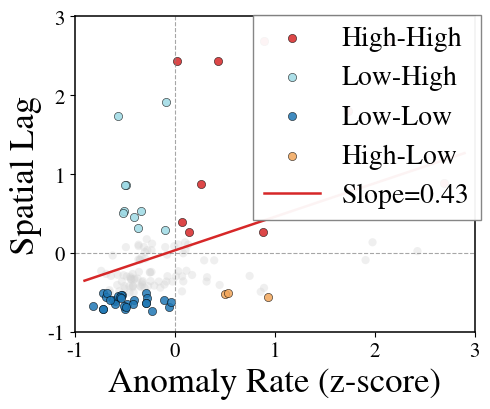

In [20]:
plot_moran_scatter_sig(
    df=geo_data,
    z_col="z_high",
    lag_col="lag_high",
    cluster_col="cluster_high",
    title=None,
    xlabel=r"Anomaly Rate (z-score)",
    ylabel=r"Spatial Lag",
    show_fit=True,
    loc = 'upper right',
    fontsize = 20,
    xlim=(-1,3),
    ylim=(-1,3)
)